# Why does the true connectome underperform its surrogates? A harmonic-weighting / localization investigation

`index.qmd` reports that substituting the true tractography-based connectome
with any of four graph-based dMRI-free surrogates (`fused`, `fused-bin`,
`geom-atlas`, `geom-atlas-bin`) or the pure-geometry `beltrami` eigenbasis
leaves wCSET's reconstruction accuracy unchanged or *significantly improves*
it. The comparison that's actually significant is **true connectome vs. every
surrogate** — there is no clean win between surrogates themselves (no
significant pairwise differences among them).

An earlier visual pass (scrolling through harmonics with `mm.viz.plot_eigvec`)
and a graph-metrics pass (edge count, degree/weight distributions, adjacency
heatmaps) didn't turn up an obvious visual difference — except a tendency for
the true connectome's harmonics to form spatially clustered "packs" rather
than vary smoothly. This notebook follows that lead quantitatively instead of
by eye, using the **inverse participation ratio (IPR)** of each harmonic,
weighted by how much that harmonic actually matters to the wCSET
reconstruction.

Structure:
1. Eigenvalue spectra, per condition.
2. The reconstruction weight wCSET actually assigns each harmonic (`harm=5,
   harmonic_method="lowpass"` for the true connectome + its four graph-based
   surrogates; a different mechanism, `harmonic_method="logpass", cutoff=150`,
   for `beltrami`).
3. The inverse participation ratio of each harmonic — what it measures, and
   how localized/clustered each condition's harmonics are.
4. What this can (and can't) explain about the reconstruction accuracy gap.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.data_manager import SimfManager

dm = SimfManager("simf.config.yml")
sub = "10"

# true connectome + its four graph-based surrogates: wCSET reconstructs all
# five with the SAME weighting mechanism (harm=5, harmonic_method="lowpass"),
# so their harmonic weights are directly comparable to each other.
LOWPASS_CONDS = ["original", "fused", "fused-bin", "geom-atlas", "geom-atlas-bin"]
HARM = 5

# beltrami uses a different mechanism entirely (Wang et al. 2026's GBF
# log-form spectral prior): harmonic_method="logpass", depth=0, cutoff=150.
# Its weights are NOT on the same footing as the lowpass ones -- treat it as
# a secondary, less directly comparable data point throughout.
LOGPASS_CUTOFF = 150

ALL_CONDS = LOWPASS_CONDS + ["beltrami"]

def load_eig(desc):
    """Load harmonics; 'original' means the true connectome (no desc entity)."""
    kwargs = {} if desc == "original" else {"desc": desc}
    eig = dm.load(sub, "eig", **kwargs)
    return eig["vec"], eig["val"]

eigs = {d: load_eig(d) for d in ALL_CONDS}
for name, (vec, val) in eigs.items():
    print(f"{name:>14s}: eigvec={vec.shape}, eigval={val.shape}, "
          f"eigval range=[{val.min():.4g}, {val.max():.4g}]")

      original: eigvec=(7465, 7465), eigval=(7465,), eigval range=[0, 1.312]
         fused: eigvec=(7465, 7465), eigval=(7465,), eigval range=[0, 1.195]
     fused-bin: eigvec=(7465, 7465), eigval=(7465,), eigval range=[0, 1.399]
    geom-atlas: eigvec=(7465, 7465), eigval=(7465,), eigval range=[0, 1.198]
geom-atlas-bin: eigvec=(7465, 7465), eigval=(7465,), eigval range=[0, 1.22]
      beltrami: eigvec=(7465, 7464), eigval=(7464,), eigval range=[0, 4.706]


## 1. Eigenvalue spectra

Each condition's harmonics come from a different operator: the true/graph
surrogates' eigenvalues are from the *normalized* graph Laplacian (bounded to
`[0, 2]`), while `beltrami`'s are from a continuous mesh Laplace-Beltrami
operator (unbounded, different units entirely) — so don't compare raw
eigenvalue magnitudes across the two families directly. We show the first
300 harmonics: this comfortably covers `beltrami`'s entire `cutoff=150`
window, plus the range where most of the other conditions' `lowpass` weight
mass lives (see next section).

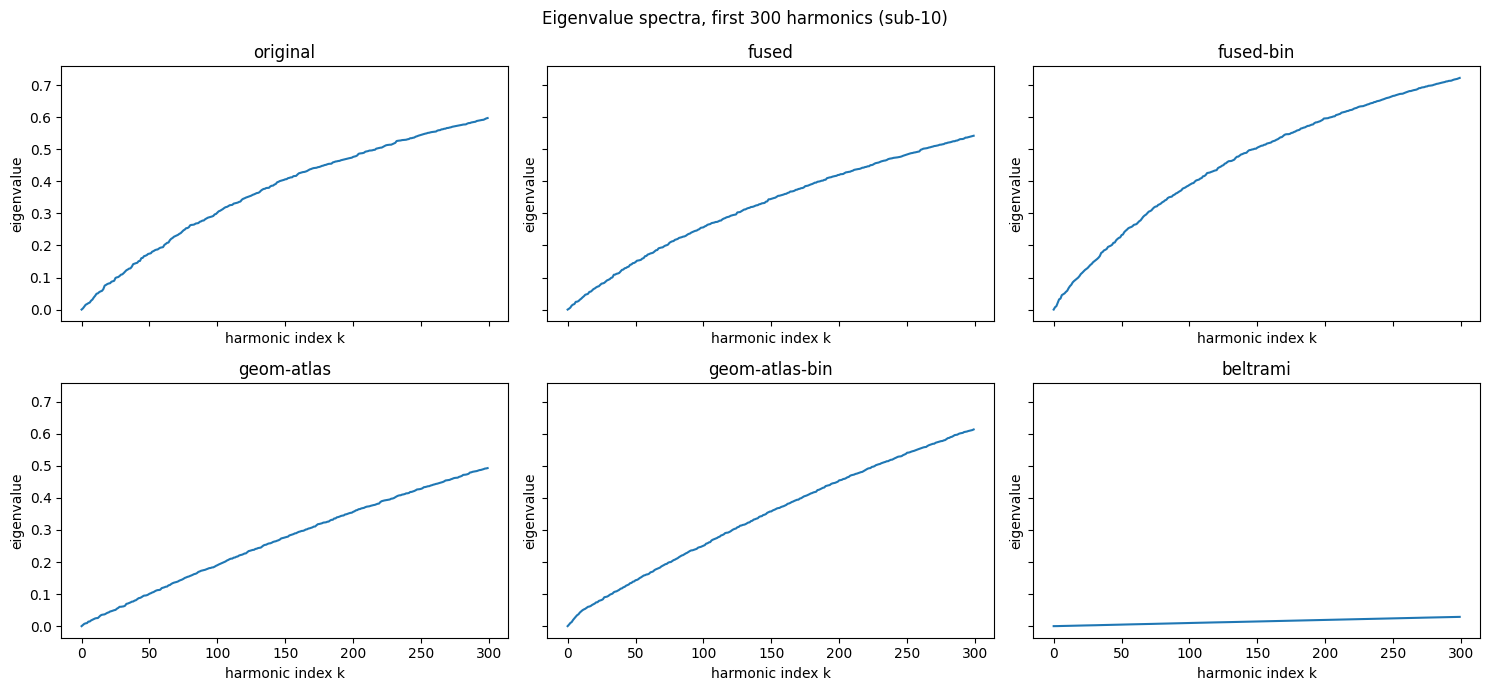

In [2]:
N_SHOW = 300

fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, name in zip(axs.flat, ALL_CONDS):
    val = eigs[name][1]
    ax.plot(val[:N_SHOW])
    ax.set_title(name)
    ax.set_xlabel("harmonic index k")
    ax.set_ylabel("eigenvalue")
fig.suptitle(f"Eigenvalue spectra, first {N_SHOW} harmonics (sub-{sub})")
plt.tight_layout()
plt.show()

## 2. Reconstruction weight per harmonic

`wCSET` doesn't use the eigenvectors unweighted — it rescales each harmonic
column by a weight before using them as the reconstruction's spatial prior
(`mindmap`'s `compute_harmonic_prior`, `self.U * w_harm` in
`wCSET.compute_source_prior`):

- **`lowpass`** (true connectome + `fused`/`fused-bin`/`geom-atlas`/`geom-atlas-bin`,
  `harm=5`): `weight_k = exp(-5 * eigval_k)`, no truncation — a smooth
  exponential low-pass filter on each eigenvalue's own magnitude.
- **`logpass`** (`beltrami`, `cutoff=150`): `weight_k = sqrt(-log(eigval_k /
  eigval_149)) ` for `k < 150`, and **exactly 0** beyond — nearly flat across
  the retained modes, then a hard wall at the cutoff. (`beta` is in the
  formula for parity with the paper it's from, but is mathematically inert
  here — `wCSET`'s own renormalization cancels it exactly.)

These weights are what makes a harmonic matter (or not) to the
reconstruction — this is the lens the rest of the notebook uses.

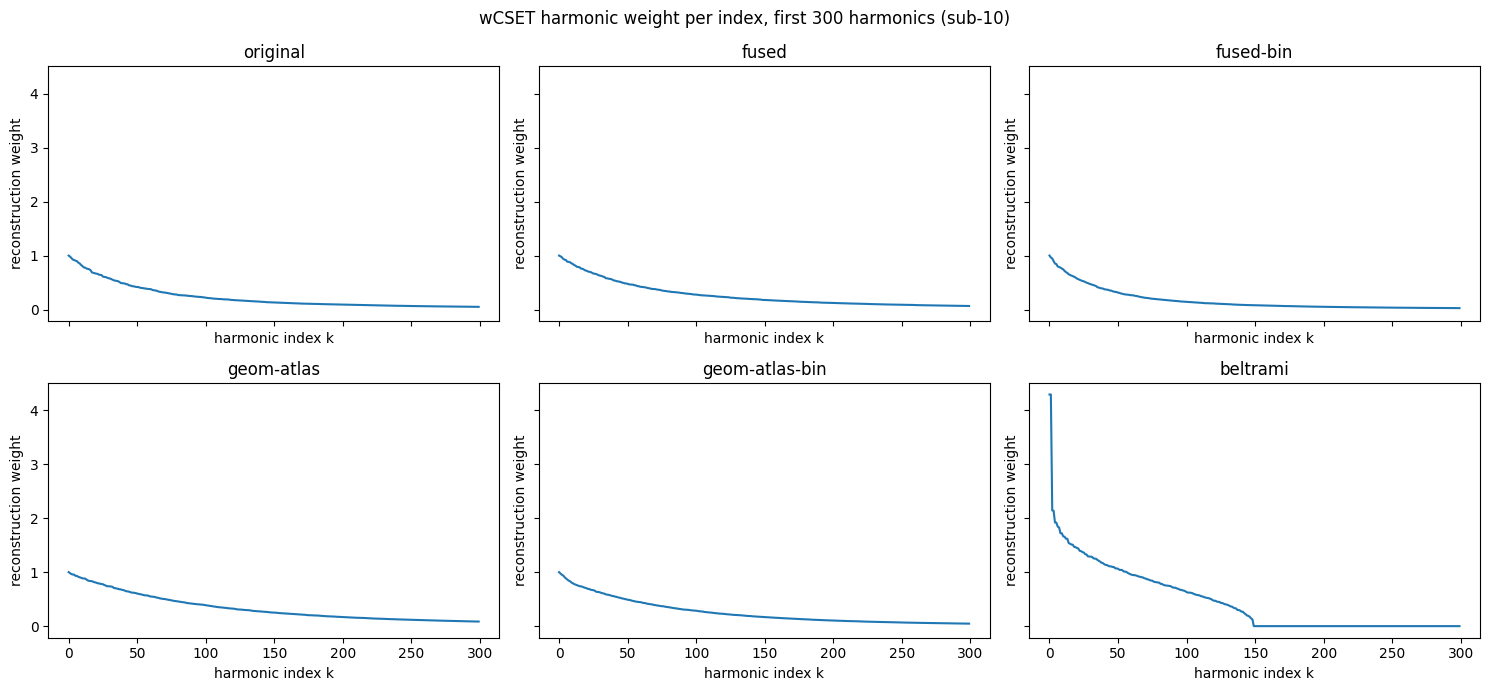

In [3]:
def lowpass_weight(val, harm=HARM):
    return np.exp(-harm * val)

def logpass_weight(val, cutoff=LOGPASS_CUTOFF):
    w = np.zeros_like(val)
    lam_cutoff = val[cutoff - 1]
    normalized = np.clip(val[:cutoff] / lam_cutoff, 1e-8, 1.0)
    w[:cutoff] = np.sqrt(-np.log(normalized))  # beta=1: shape-inert, see markdown above
    return w

weights = {name: lowpass_weight(eigs[name][1]) for name in LOWPASS_CONDS}
weights["beltrami"] = logpass_weight(eigs["beltrami"][1])

fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, name in zip(axs.flat, ALL_CONDS):
    ax.plot(weights[name][:N_SHOW])
    ax.set_title(name)
    ax.set_xlabel("harmonic index k")
    ax.set_ylabel("reconstruction weight")
fig.suptitle(f"wCSET harmonic weight per index, first {N_SHOW} harmonics (sub-{sub})")
plt.tight_layout()
plt.show()

## 3. Inverse participation ratio (IPR)

Every harmonic here is an orthonormal eigenvector `x` (`sum(x_i^2) = 1`
across the `n_dipoles` dipoles). Treat `p_i = x_i^2` as a distribution of
that harmonic's "energy" over the cortex. The **inverse participation
ratio** is

```
IPR = sum(p_i^2) = sum(x_i^4)
```

- If a harmonic is spread perfectly evenly (`p_i = 1/n_dipoles` everywhere),
  `IPR = 1/n_dipoles` — the smallest possible value.
- If a harmonic is concentrated on a single dipole, `IPR = 1` — the largest
  possible value.
- In between, `1/IPR` is roughly "how many dipoles this harmonic's energy is
  effectively spread across" — a harmonic living on one small, spatially
  disjoint cluster (a "pack") has a much higher IPR than one that varies
  smoothly across the whole cortical sheet.

This is the participation ratio from condensed-matter physics (used to tell
localized from extended wavefunctions, e.g. Anderson localization), applied
here to cortical harmonics instead of quantum states.

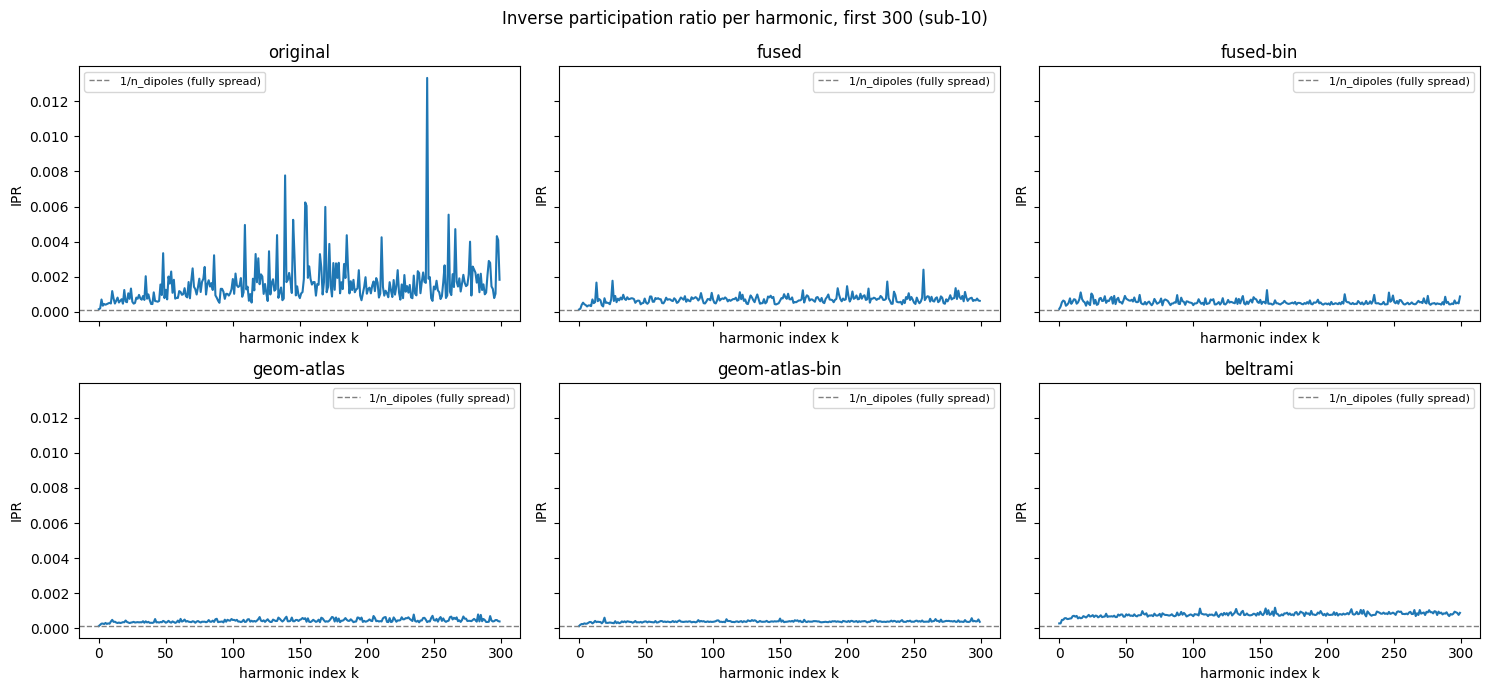

In [4]:
def ipr(eigvec):
    """eigvec: (n_dipoles, n_modes), orthonormal columns (sum x^2 = 1 per column)."""
    p = eigvec**2
    return np.sum(p**2, axis=0)

iprs = {name: ipr(eigs[name][0]) for name in ALL_CONDS}

fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, name in zip(axs.flat, ALL_CONDS):
    n_dipoles = eigs[name][0].shape[0]
    ax.plot(iprs[name][:N_SHOW])
    ax.axhline(1 / n_dipoles, color="gray", ls="--", lw=1, label="1/n_dipoles (fully spread)")
    ax.set_title(name)
    ax.set_xlabel("harmonic index k")
    ax.set_ylabel("IPR")
    ax.legend(fontsize=8)
fig.suptitle(f"Inverse participation ratio per harmonic, first {N_SHOW} (sub-{sub})")
plt.tight_layout()
plt.show()

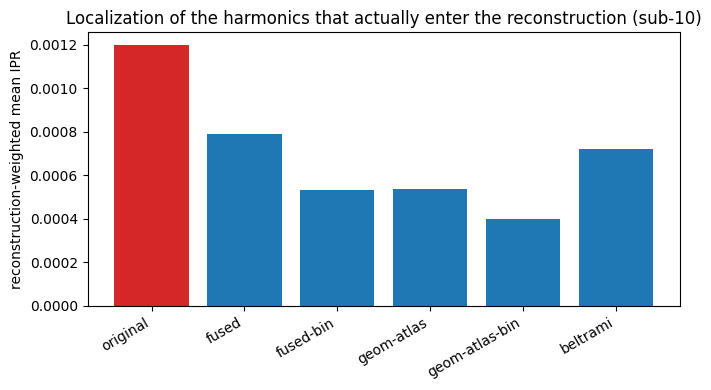

      original: weighted mean IPR = 0.001196
         fused: weighted mean IPR = 0.000790
     fused-bin: weighted mean IPR = 0.000533
    geom-atlas: weighted mean IPR = 0.000536
geom-atlas-bin: weighted mean IPR = 0.000400
      beltrami: weighted mean IPR = 0.000720


In [5]:
# Reconstruction-weighted mean IPR: "how localized are the harmonics that
# actually matter to the reconstruction", collapsed to one number per
# condition. Excludes each condition's trivial constant/near-constant mode(s)
# (k=0 for the graph Laplacian conditions; k=0,1 for beltrami, one per
# independently-solved hemisphere) -- those carry the top weight by
# construction but are, by definition, maximally spread out (IPR ~ 1/n_dipoles)
# regardless of graph structure, so including them would dilute the signal.
summary = {}
for name in LOWPASS_CONDS:
    w, p = weights[name][1:], iprs[name][1:]
    summary[name] = np.sum(w * p) / np.sum(w)

w_b, p_b = weights["beltrami"][2:], iprs["beltrami"][2:]
summary["beltrami"] = np.sum(w_b * p_b) / np.sum(w_b)

fig, ax = plt.subplots(figsize=(7, 4))
names = list(summary.keys())
colors = ["#d62728" if n == "original" else "#1f77b4" for n in names]
ax.bar(names, [summary[n] for n in names], color=colors)
ax.set_ylabel("reconstruction-weighted mean IPR")
ax.set_title(f"Localization of the harmonics that actually enter the reconstruction (sub-{sub})")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

for n in names:
    print(f"{n:>14s}: weighted mean IPR = {summary[n]:.6f}")

In [6]:
# Practical follow-up: the specific harmonics driving each condition's IPR,
# to look up directly in the interactive viewer below.
#
# Restricted to k < N_SHOW (same window as the plots above), NOT the full
# spectrum: dense eigh's last few columns near the top of a large, nearly
# degenerate spectrum are numerically unstable and can produce spuriously
# near-single-dipole eigenvectors (IPR close to 1) with negligible (<0.3%)
# weight -- real, but practically irrelevant to the reconstruction, and not
# what we're after here.
print(f"Top-5 most localized, non-trivial harmonics by (weight x IPR), k<{N_SHOW}, per condition:\n")
for name in LOWPASS_CONDS:
    w, p = weights[name][:N_SHOW].copy(), iprs[name][:N_SHOW]
    score = w * p
    score[0] = -1  # exclude trivial constant mode
    order = np.argsort(score)[::-1][:5]
    print(f"{name}:")
    for k in order:
        print(f"    k={k:4d}  eigval={eigs[name][1][k]:.5f}  weight={w[k]:.4f}  IPR={p[k]:.5f}")
    print()

Top-5 most localized, non-trivial harmonics by (weight x IPR), k<300, per condition:

original:
    k=  48  eigval=0.16983  weight=0.4278  IPR=0.00334
    k= 139  eigval=0.38416  weight=0.1465  IPR=0.00777
    k=  35  eigval=0.12779  weight=0.5278  IPR=0.00203
    k= 109  eigval=0.32533  weight=0.1966  IPR=0.00495
    k=  10  eigval=0.04292  weight=0.8069  IPR=0.00119

fused:
    k=  13  eigval=0.04633  weight=0.7932  IPR=0.00167
    k=  25  eigval=0.08082  weight=0.6676  IPR=0.00178
    k=  10  eigval=0.03390  weight=0.8441  IPR=0.00071
    k=  27  eigval=0.08337  weight=0.6591  IPR=0.00091
    k=  33  eigval=0.10031  weight=0.6056  IPR=0.00098

fused-bin:
    k=  16  eigval=0.09245  weight=0.6299  IPR=0.00111
    k=   8  eigval=0.05038  weight=0.7773  IPR=0.00077
    k=   3  eigval=0.02164  weight=0.8974  IPR=0.00065
    k=  24  eigval=0.12627  weight=0.5319  IPR=0.00105
    k=   2  eigval=0.01071  weight=0.9478  IPR=0.00055

geom-atlas:
    k=  10  eigval=0.02406  weight=0.8867  IPR

## 4. How the participation ratio can explain differences in reconstruction

`wCSET`'s source prior is `w_depth[:, None] * (U * w_harm)` — the weighted
eigenvectors aren't a side detail, they **are** the spatial basis the inverse
solve is regularized toward. A harmonic with a high reconstruction weight and
a high IPR is a specific, rigid hypothesis: "these few, possibly spatially
disjoint dipoles should activate together, and hardly anything else."

- If the simulated (or real) source activity happens to follow that same
  cluster — because it genuinely reflects a real white-matter tract — the
  prior helps.
- If it doesn't — because the tract is a tractography false positive, a real
  but reconstruction-irrelevant connection for this particular simulated
  source, or just because the parcellation/streamline-counting pipeline is
  noisy at single-subject, dipole resolution — the prior actively fights the
  true, smoothly-spreading activity, pulling the reconstruction toward the
  unrelated cluster instead.

A low-IPR harmonic is a far more generic, forgiving assumption — "activity
varies slowly across the cortex" — that doesn't commit to any one
subject-specific, error-prone long-range connection.

**What the numbers above show:** the true connectome's reconstruction-weighted
harmonics are more localized than every one of its four graph-based
surrogates, consistently across the first ~30 harmonics (not just a couple of
outliers), and the effect survives collapsing to the single weighted-mean-IPR
number. That matches the *actual* significant result — true connectome vs.
every surrogate — rather than any ranking between surrogates, which isn't
significant either in accuracy or, here, in IPR: the four surrogates don't
separate cleanly from each other, only from `original`.

**Caveats, to keep this honest:**

- This is a plausible, quantitative, and specific candidate mechanism — not
  a proof. It's a correlation between one property of the harmonic basis and
  a known accuracy gap, not a causal ablation.
- `beltrami` uses a completely different weighting mechanism (flat weight
  over a hard 150-mode cutoff, not exponential decay by eigenvalue
  magnitude), so its IPR number isn't on the same footing as the other four
  and shouldn't be read into the same comparison with the same confidence.
- Near-zero eigenvalue *counts* (a naive "is the graph nearly disconnected"
  check) do **not** separate the conditions — `geom-atlas` actually has more
  near-zero eigenvalues than `original`. It's specifically the
  *reconstruction-weighted localization* of the harmonics, not raw spectral
  density, that tracks the split we're looking for.

## Interactive harmonics viewer (external window, arrow-key scrolling)

Use `scripts/view_harmonics.py` to look directly at the specific harmonics
flagged above (external PyVista window — Jupyter's inline renderer would
swallow the arrow-key events). Pass several `--desc` values to compare
conditions side by side in linked panels with one shared slider.

In [ ]:
# All five lowpass-weighted conditions side by side, linked panels, one shared slider.
# Use the slider / Left-Right keys to jump to the harmonic indices printed above.
!python -m scripts.view_harmonics --desc original fused fused-bin geom-atlas geom-atlas-bin